# 🧹 Machine Unlearning for Responsible AI
### Read this FIRST

Welcome. This repository teaches **machine unlearning** - how to make a trained AI model *forget* specific data - and
how to **prove** that it actually did. It is written for two readers at once:

> 🟢 **In plain words** boxes are for you if you are new. No maths, just the idea, usually with an analogy.
>
> 🔴 **For practitioners** boxes are for Responsible-AI engineers who want the formal definition, the assumptions,
> the paper section, and the way it fails in production.

Read both if you can. Every notebook follows the same rhythm, so you always know where you are :

| Step | What happens | Why |
|---|---|---|
| 1. **Train** | train a model on data that includes something it should not keep | create the problem |
| 2. **Show the issue** | measure how the model still carries that data | make the problem visible |
| 3. **Untrain** | apply an unlearning method | attempt the fix |
| 4. **Show the result** | re-measure, side by side with *before* | see the difference |
| 5. **Prove it** | compare with a model that *never* saw the data | the only honest test |

Everything runs on a laptop CPU in seconds. Classical models use NumPy and scikit-learn; the neural networks are written
in **pure NumPy** - every gradient is a line of code you can read. (One optional notebook, 16b, repeats the LLM lesson
in PyTorch.)

----

### 1. What is machine unlearning?

![Deleting a row vs unlearning](assets/diagrams/01_delete_vs_unlearn.png)

> 🟢 **In plain words :** you can tear a page out of a cookbook, but you cannot "un-bake" the cake you made from it.
> A trained model is the cake. Deleting the training data (the page) does not remove what the model learned from it.
> **Machine unlearning** is the set of techniques for "un-baking" - removing the influence of specific data from a
> model that has already been trained.

> 🔴 **For practitioners :** given a learning algorithm `A`, a dataset `D`, and a forget set `D_f ⊂ D`, an unlearning
> algorithm `U` maps `(A(D), D, D_f) → θ_u`. **Exact** unlearning requires `θ_u` to be identically distributed to
> `A(D \ D_f)` (Cao & Yang 2015; Bourtoule et al. 2021). **Approximate** unlearning relaxes this to "close" under some
> divergence - formalised as (ε, δ)-unlearning by analogy with differential privacy (Guo et al. 2019; Ginart et al. 2019),
> or, in practice, *empirically indistinguishable* under the strongest audit you can run (Hayes et al. 2024).

----

### 2. Why would anyone need it? (real cases, not hypotheticals)

| Situation | Example | What has to be forgotten |
|---|---|---|
| **Right to be Forgotten** | GDPR Art. 17, India's DPDP Act 2023 s.12, California CCPA §1798.105 give people the right to have their personal data erased | one person's records |
| **Unlawfully collected data** | FTC v. **Everalbum** (2021): delete the face-recognition models built from users' photos. FTC v. **WW/Kurbo** (2022): destroy algorithms derived from children's data. FTC v. **Rite Aid** (2023): delete "any data, models, or algorithms derived" from the facial images | a whole data source - regulators already order *model* deletion ("algorithmic disgorgement") |
| **Is a model personal data?** | EDPB Opinion 28/2024: a model trained on personal data is only "anonymous" if extracting that data from it is *negligible*, including through queries | anything the model could leak |
| **Consent revoked** | a person withdraws consent for their face / voice / health record | one identity |
| **Poisoned data** | an attacker slipped mislabelled or back-doored samples into training | the malicious samples |
| **Copyright / licensing** | a data licence expires or a rights-holder objects | one source |
| **Harmful knowledge in LLMs** | hazardous instructions, memorised secrets, private phone numbers | facts, not rows |

> 🟢 **In plain words :** the law increasingly says "delete it" - and regulators have already said "and delete the
> model you built with it". Unlearning is how you comply *without* throwing away the whole model every time.

> 🔴 **For practitioners :** the FTC orders above required destroying *models*, not just data - unlearning is the
> cheaper alternative, but only if you can evidence it. Problem 17 turns that into an engineering playbook. Sources for
> every case are listed in `resources/README.md` and `README.md`.

----

### 3. The notation used in every notebook

![Notation](assets/diagrams/02_notation.png)

| Symbol | Meaning |
|---|---|
| `D` | the full training set |
| `D_f` | the **forget set** - data that must be removed |
| `D_r` | the **retain set** - everything else (`D = D_r ∪ D_f`) |
| `D_test` | data the model never trained on, used to measure usefulness |
| `θ_o` | the **original** model, trained on `D` |
| `θ_r` | the **retrained** model, trained on `D_r` only - the **gold standard** |
| `θ_u` | the **unlearned** model, produced by an unlearning method from `θ_o` |

The single most important idea in the whole repository :

![The goal](assets/diagrams/03_unlearning_goal.png)

> 🟢 **In plain words :** the perfect answer is always "the model you would have had if the data had never been there".
> We can compute that answer by retraining from scratch - it is just slow and expensive. Every clever method tries to
> get the same answer cheaply, and every test checks how close it got.

----

### 4. The map of methods

![Taxonomy](assets/diagrams/04_taxonomy.png)

| Family | Guarantee | Cost | Problems |
|---|---|---|---|
| **Exact, classical** - delete, subtract, downdate, retrain-a-part | the result *provably* equals retraining | tiny | 01, 02, 03, 13, 14, 16 |
| **Exact, neural** - retrain, SISA, adapters, re-fine-tune from a checkpoint | the result *provably* equals retraining | high, or requires planning at training time | 06, 07, 15, 16 |
| **Approximate** - Newton step, fine-tune, gradient ascent, NegGrad+, SCRUB, Bad Teacher, task vectors, NPO | none - must be **audited** | low | 02, 08, 09, 10, 15, 16 |
| **Auditing** - membership inference, gold band, relearn attack, exposure, fairness | tells you whether the above worked | moderate | 05, 11, 12, 16 |

----

### 5. Vocabulary you will meet

| Term | 🟢 Plain words | 🔴 Precise meaning |
|---|---|---|
| **Memorisation** | the model remembers a specific example, not just the general pattern | the model's behaviour on `x` changes significantly when `x` is removed from training (Feldman 2020) |
| **Membership inference attack (MIA)** | an attacker guesses whether *your* data was used to train the model | a binary test on model outputs; strength reported as AUC and TPR at low FPR (Shokri 2017; Carlini 2022) |
| **Gold standard / gold band** | what a model that never saw the data does | the distribution of metrics over several retrains on `D_r` with different seeds |
| **Over-forgetting** | the model is *suspiciously* bad on the deleted data | forget-set error above the retrain band - itself a membership signal ("Streisand effect") |
| **Relearn attack** | can the forgotten knowledge be brought back quickly? | steps of fine-tuning on (part of) `D_f` needed to recover; fast recovery ⇒ suppression, not removal |
| **Teacher / student** | copy a model's behaviour into another model | knowledge distillation: minimise KL(teacher ‖ student) on softened outputs (Hinton et al. 2015) |
| **Gradient ascent** | train the model to get *worse* on some data | step along +∇L instead of −∇L |
| **KL divergence** | how different two probability predictions are | KL(p‖q) = Σ p log(p/q) |
| **Utility** | is the model still useful? | accuracy on `D_r` and `D_test` |

----

### 6. A 60-second preview of the whole course

Below is the full loop in four code cells : **train → show the issue → untrain → prove it**. Don't worry about the details
yet; every line is explained in later notebooks.

The setup: a digit-recognition model is trained on 1,257 handwritten digits. **Forty of them were written by one person,
Carol, with a thick marker** - a style nobody else in the data has. Carol now asks to be deleted.

Lab('carol': |D|=1257, |D_f|=40, |D_r|=1217, |test|=540)
Carol contributed 40 thick-marker digits and invokes her right to erasure.


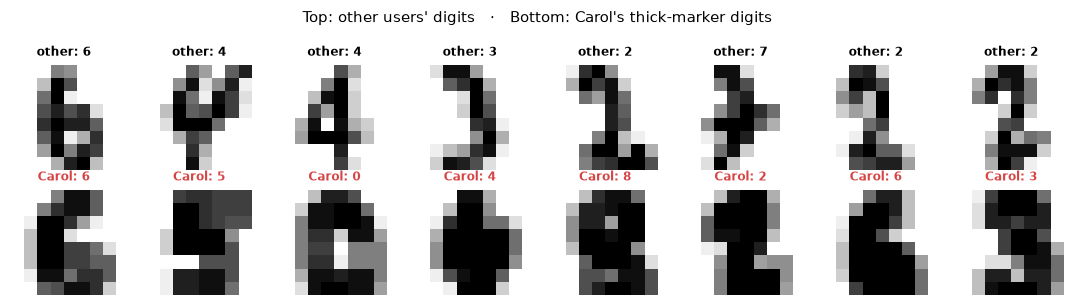

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mul import lab, train, methods, viz
viz.style()

L = lab.make_lab("carol")          # the digits 'lab' + Carol's 40 thick-marker digits
print(L)
print(L.description)

fig, axes = plt.subplots(2, 8, figsize=(10, 2.8))
for i, ax in enumerate(axes[0]):
    ax.imshow(L.Xr[i].reshape(8, 8), cmap="gray_r"); ax.axis("off"); ax.set_title(f"other: {L.yr[i]}", fontsize=8)
for i, ax in enumerate(axes[1]):
    ax.imshow(L.Xf[i].reshape(8, 8), cmap="gray_r"); ax.axis("off"); ax.set_title(f"Carol: {L.yf[i]}", fontsize=8, color=viz.FORGET)
plt.suptitle("Top: other users' digits   ·   Bottom: Carol's thick-marker digits", fontsize=10); plt.tight_layout(); plt.show()

**Step 1 - Train**, and **Step 2 - show the issue**: how well does the model know *Carol's own* digits, compared with
thick-marker digits it has never seen?

In [2]:
original = train.fit(lab.model_fn, L.X_train, L.y_train, seed=0, **lab.FIT)

print(f"Original model  | accuracy on Carol's own digits          : {train.accuracy(original, L.Xf, L.yf):6.1%}")
print(f"                | accuracy on unseen thick-marker digits  : {train.accuracy(original, L.X_like_forget, L.y_like_forget):6.1%}")
print(f"                | accuracy on everyone else's test digits : {train.accuracy(original, L.X_test, L.y_test):6.1%}")

Original model  | accuracy on Carol's own digits          : 100.0%
                | accuracy on unseen thick-marker digits  :  77.5%
                | accuracy on everyone else's test digits :  98.0%


The model is **100%** right on Carol's own digits but noticeably worse on thick-marker digits it never saw. That gap is
Carol's *fingerprint* inside the weights: the model did not just learn "thick digits", it memorised **hers**.

Deleting her rows from the database now changes nothing - the weights are already trained. **Step 3 - untrain** (here
with the simplest exact method, retraining without her), and **Step 4 - show the result**:

In [3]:
retrained, info = methods.retrain(lab.model_fn, L.Xr, L.yr, seed=0, **lab.FIT)

rows = [("original  (saw Carol)", original), ("retrained (never saw Carol)", retrained)]
print(f"{'model':30s} {'Carol (D_f)':>12s} {'unseen thick':>13s} {'test':>8s}")
for name, m in rows:
    print(f"{name:30s} {train.accuracy(m, L.Xf, L.yf):12.1%} {train.accuracy(m, L.X_like_forget, L.y_like_forget):13.1%} "
          f"{train.accuracy(m, L.X_test, L.y_test):8.1%}")

model                           Carol (D_f)  unseen thick     test
original  (saw Carol)                100.0%         77.5%    98.0%
retrained (never saw Carol)           55.0%         62.5%    98.0%


**Step 5 - prove it**: after retraining, the model treats Carol's digits *exactly like any other unseen thick-marker
digits* - her own data no longer gets special treatment, and everyone else's accuracy is unchanged. That is what
"forgotten" means.

Notice that it is **not 0%**. A model that never met Carol can still read many of her digits, because it learned what
digits look like from everyone else. Forgetting Carol means *removing her specific influence*, not making the model blind
to her. This one idea - **the target is the retrained model, not zero** - is what most unlearning tutorials get wrong.

The catch: retraining is affordable for a 0.3-second model. For a model that costs weeks of GPU time, it is not - and
that is where the rest of the course begins.

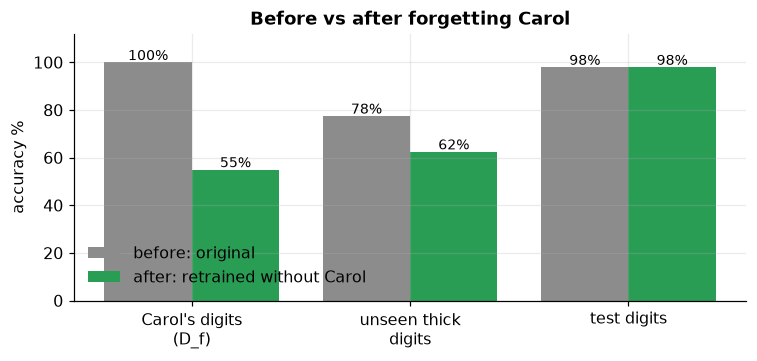

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.4))
names = ["Carol's digits\n(D_f)", "unseen thick\ndigits", "test digits"]
vals_o = [train.accuracy(original, L.Xf, L.yf), train.accuracy(original, L.X_like_forget, L.y_like_forget), train.accuracy(original, L.X_test, L.y_test)]
vals_r = [train.accuracy(retrained, L.Xf, L.yf), train.accuracy(retrained, L.X_like_forget, L.y_like_forget), train.accuracy(retrained, L.X_test, L.y_test)]
x = np.arange(3)
ax.bar(x - 0.2, np.array(vals_o) * 100, 0.4, color=viz.ORIGINAL, label="before: original")
ax.bar(x + 0.2, np.array(vals_r) * 100, 0.4, color=viz.RETRAIN, label="after: retrained without Carol")
for i in range(3):
    ax.text(i - 0.2, vals_o[i] * 100 + 1, f"{vals_o[i]:.0%}", ha="center", fontsize=9)
    ax.text(i + 0.2, vals_r[i] * 100 + 1, f"{vals_r[i]:.0%}", ha="center", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylabel("accuracy %"); ax.set_ylim(0, 112)
ax.set_title("Before vs after forgetting Carol"); ax.legend(loc="lower left"); plt.tight_layout(); plt.show()

----
### 7. How to proceed - the Ladder of Forgetting

The notebooks are **one argument, built rung by rung**. Each notebook starts from the limitation the previous one ran
into, and climbs one step - from models where forgetting is a subtraction, to large language models where nobody can
yet do it reliably.

![The Ladder of Forgetting](assets/diagrams/00_ladder_of_forgetting.png)

| Stage | Problems | The question |
|---|---|---|
| 0. Foundations | `00` | what is unlearning and why does it matter? |
| 1. Classical ML | `01`, `02`, `03` | when is forgetting exact and cheap - and what property makes it so? |
| 2. Neural networks: the problem | `04`, `05` | what breaks when every data point touches every weight, and how do we detect what is left? |
| 3. Exact unlearning for neural nets | `06`, `07` | how do we forget *provably* when there is no closed form? |
| 4. Approximate unlearning | `08`, `09`, `10` | how do we forget *cheaply* an already-trained model, and what can go wrong? |
| 5. Proof | `11` | how do we know it worked? |
| 6. Real-world Responsible AI | `12` - `16`, `16b` | right to be forgotten and fairness, consent in face ID, poisoning, fine-tuning per customer, LLM facts - classical first, then deep |
| 7. Engineering | `17` | how do we run this in production, before a legal deadline, with evidence? |
| 8. Extensions | `18`, `19` | do the same ideas hold for recommenders, and for every method the research world offers? |

Every problem opens with **🔗 Building on** (what we carry over) and closes with **❓ Open question** (what forces the
next rung). Follow them in order: the **[ROADMAP](ROADMAP.md)** has time estimates and checkpoints.

When you are done, test yourself with **[PRACTICE.md](PRACTICE.md)**. Papers for every notebook are in
`resources/papers/` and indexed in `resources/README.md`.

----
#### Key Takeaways :

- Deleting training data does **not** remove its influence from a trained model.
- The gold standard is a model **retrained without** the data - forgetting means matching it, not scoring zero.
- Exact methods guarantee that match; approximate methods are cheaper but must be **audited**.
- Regulators already order model deletion; unlearning plus evidence is the alternative.

#### TASK :
1. Change `lab.make_lab("carol")` to `lab.make_lab("random")` and re-run. Why is the before/after difference so much
   smaller for randomly chosen users than for Carol?
2. Retrain with `seed=1`, `seed=2` and `seed=3`. Does the retrained model's accuracy on Carol's digits change? What does
   that tell you about using *one* retrained model as "the" gold standard? (Problem 6 answers this.)
3. In one sentence each, explain to a non-technical colleague the difference between *deleting* data and *unlearning* it.